In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Task1_Data_Cleaning.csv", parse_dates=["join_date"])
df["join_year"] = df["join_date"].dt.year
sns.set_theme(style="whitegrid", palette="Set2")

**Bar chart:** average salary by department

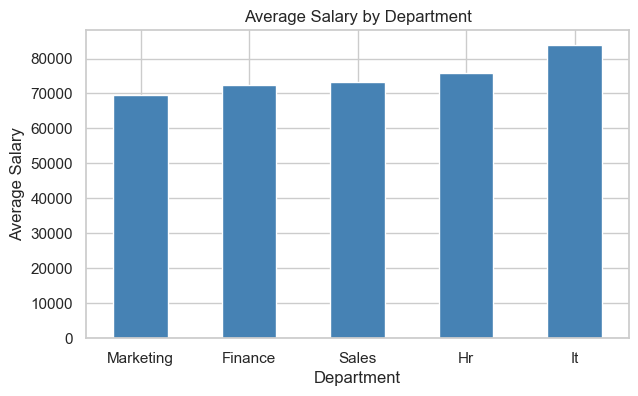

In [4]:
avg = df.groupby("department")["salary"].mean().sort_values()
avg.plot(kind="bar", color="steelblue", figsize=(7,4))
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.xticks(rotation=0)
plt.show()

IT has the highest average salary

**Line chart:** hires per year

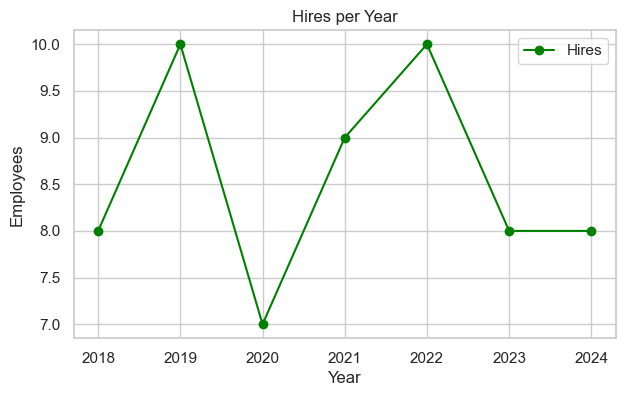

In [5]:
hires = df.groupby("join_year").size()
plt.figure(figsize=(7,4))
plt.plot(hires.index, hires.values, marker="o", color="green", label="Hires")
plt.title("Hires per Year")
plt.xlabel("Year")
plt.ylabel("Employees")
plt.legend()
plt.show()

Hiring peaked in 2019 and 2022

**Pie chart:** employees by department

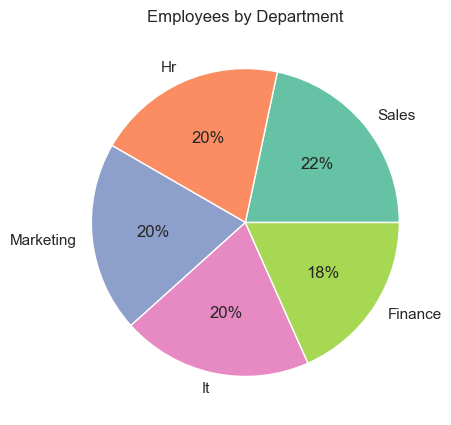

In [7]:
df["department"].value_counts().plot(kind="pie", autopct="%1.0f%%", figsize=(5,5))
plt.title("Employees by Department")
plt.ylabel("")
plt.show()

Sales is the largest department (about 22%), and Finance is the smallest (about 18%).

The workforce is evenly spread, with every department between 18% and 22%.

**Histogram:** salary distribution

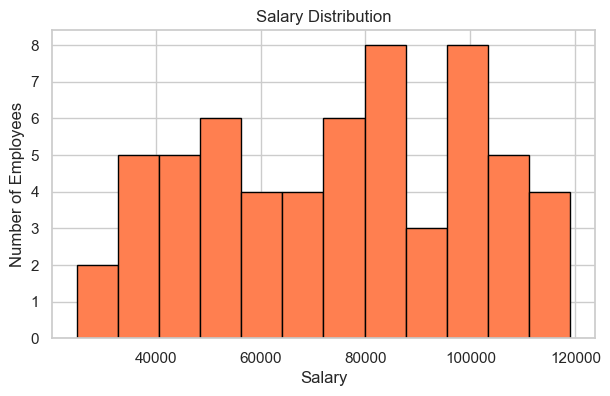

In [6]:
plt.figure(figsize=(7,4))
plt.hist(df["salary"], bins=12, color="coral", edgecolor="black")
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.show()

Salaries are spread fairly evenly from 25,000 to 119,000, with no single dominant range.

About 14 employees earn 100,000 or more, and only 7 earn under 40,000.

The median is about 78,000, so a typical employee earns in the 60,000 to 100,000 range.

**Scatter plot:** age vs salary,colored by department

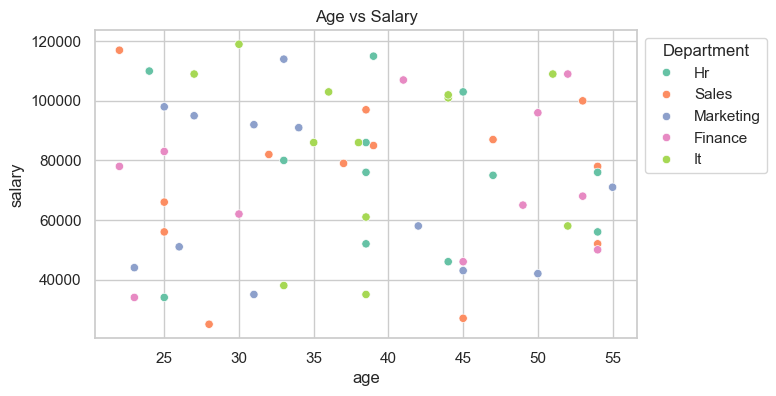

In [8]:
plt.figure(figsize=(7,4))
sns.scatterplot(data=df, x="age", y="salary", hue="department")
plt.title("Age vs Salary")
plt.legend(title="Department", bbox_to_anchor=(1,1))
plt.show()

There is no visible pattern, and the correlation is about -0.02, so age does not predict salary here.

Average salary by age group stays between about 71,000 and 79,000, so older employees don't earn more.

**Employee Dashboard**

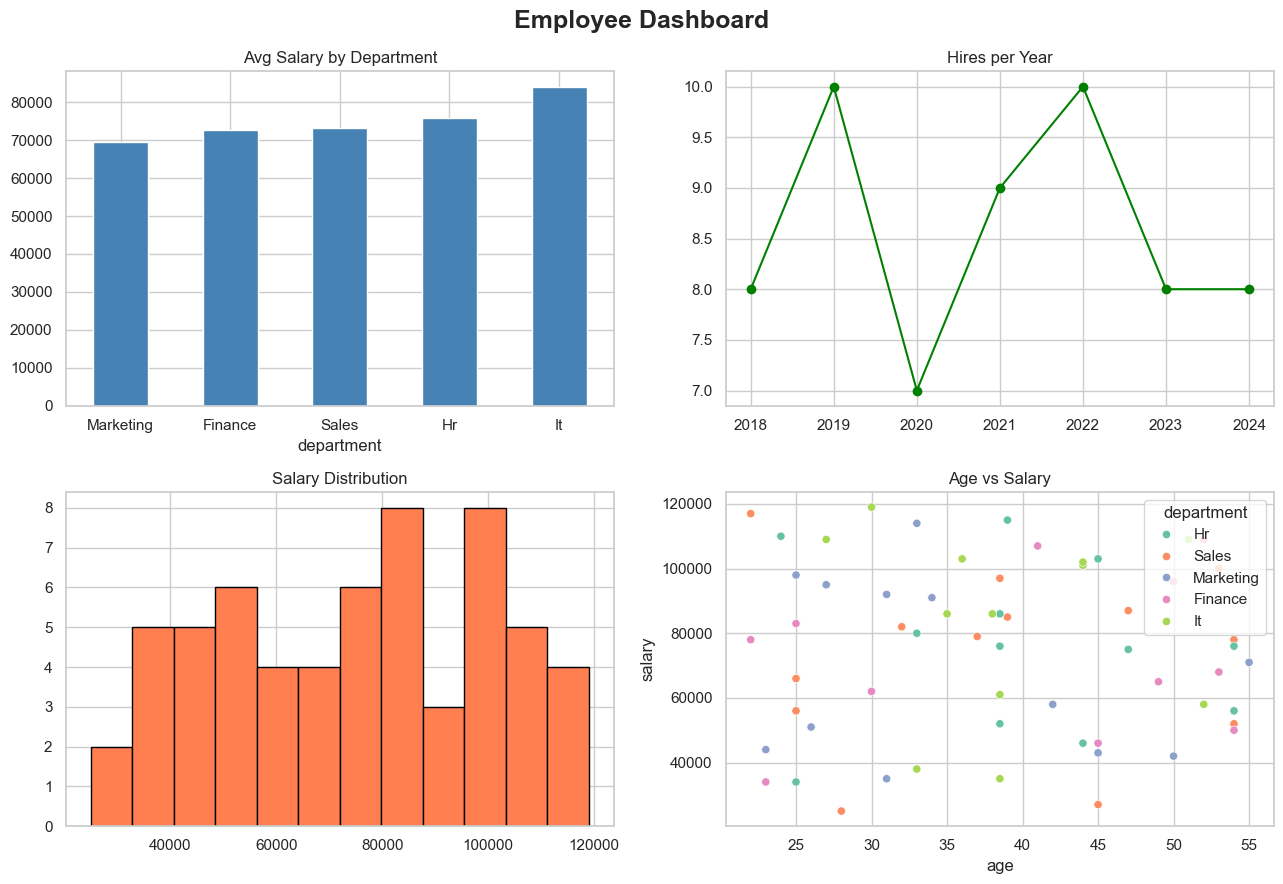

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Employee Dashboard", fontsize=18, fontweight="bold")

avg.plot(kind="bar", ax=ax[0,0], color="steelblue", title="Avg Salary by Department")
ax[0,0].tick_params(axis="x", rotation=0)

ax[0,1].plot(hires.index, hires.values, marker="o", color="green")
ax[0,1].set_title("Hires per Year")

ax[1,0].hist(df["salary"], bins=12, color="coral", edgecolor="black")
ax[1,0].set_title("Salary Distribution")

sns.scatterplot(data=df, x="age", y="salary", hue="department", ax=ax[1,1])
ax[1,1].set_title("Age vs Salary")

plt.tight_layout()
plt.savefig("dashboard.png", dpi=150)
plt.show()

Employees are evenly distributed across departments and hires are steady year to year. IT is the highest-paying department, while age has no effect on salary. Salary differences are likely driven by role and department rather than age or experience.